# Notebook 05 V2 — Incremental fine-tuning PhoBERT + CNN

Notebook này tạo **candidate V2** từ checkpoint tốt nhất V1 bằng warm-start trọng số và optimizer/scheduler mới.

- Train: `train_v2.csv` — 766 bài, gồm 740 bài V1 và 26 bài review38 đã chốt.
- Validation: giữ nguyên `validation.csv` — 159 bài.
- Test: giữ nguyên `test.csv` — 159 bài nhưng **không được đưa qua model trong notebook này**.
- Checkpoint nguồn: run V1 `20261024_153932_380173`.
- Output V2: run dễ đọc `review38_incremental_v2`, tách riêng khỏi V1.

Candidate chỉ được đề nghị sử dụng khi Macro-F1 validation cao hơn V1 ít nhất `MIN_DELTA` trên cùng validation. Notebook không ghi đè V1 và không tự chọn lại nhãn.


## 1. Thiết lập

Trên Colab, chọn GPU T4, dùng ZIP dự án mới nhất và bảo đảm checkpoint V1 đã nằm trong `MyDrive/stock_news_anomaly_project`. Có thể `Run all`; notebook sẽ dừng sớm nếu dữ liệu, hash, Java, checkpoint hoặc thư mục output không đúng.


In [1]:
import gc
import hashlib
import json
import os
import shutil
import subprocess
import sys
import zipfile
from importlib.metadata import version
from pathlib import Path
from urllib.request import urlretrieve


In [2]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import torch
    from packaging.version import Version
    if not torch.cuda.is_available():
        raise RuntimeError('Chưa có CUDA. Chọn máy GPU T4 trong Colab rồi kết nối lại.')
    if Version(torch.__version__.split('+')[0]) < Version('2.6'):
        raise RuntimeError('Cần runtime Colab có PyTorch >= 2.6; không tự thay bản CUDA hiện tại.')
    print('GPU được cấp:', torch.cuda.get_device_name(0))
    print('VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))


GPU được cấp: Tesla T4
VRAM (GB): 14.6


In [3]:
if IN_COLAB:
    colab_packages = [
        'transformers==4.57.1', 'py-vncorenlp==0.1.4',
        'pandas>=2.2,<3', 'scikit-learn>=1.7,<1.8',
        'matplotlib>=3.10,<4', 'tqdm>=4.67,<5',
    ]
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--quiet', *colab_packages,
    ])
    if shutil.which('java') is None:
        subprocess.check_call(['apt-get', '-qq', 'update'])
        subprocess.check_call(['apt-get', '-qq', 'install', '-y', 'openjdk-17-jre-headless'])


In [4]:
COLAB_OUTPUT_DIR = None
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    COLAB_OUTPUT_DIR = Path('/content/drive/MyDrive/stock_news_anomaly_project')


Mounted at /content/drive


In [5]:
COLAB_PROJECT_DIR = Path('/content/news_processing') if IN_COLAB else None
if IN_COLAB:
    project_archive = COLAB_OUTPUT_DIR / 'news_processing_v2_colab.zip'
    if not project_archive.is_file():
        project_archive = Path('/content/news_processing_v2_colab.zip')
    if project_archive.is_file():
        with zipfile.ZipFile(project_archive) as archive:
            for member in archive.infolist():
                target_path = (Path('/content') / member.filename).resolve()
                if not target_path.is_relative_to(COLAB_PROJECT_DIR.resolve()):
                    raise ValueError('Gói ZIP phải chỉ chứa thư mục news_processing.')
            archive.extractall('/content')
        print('Đã cập nhật dữ liệu/code từ:', project_archive)
    elif not COLAB_PROJECT_DIR.is_dir():
        raise FileNotFoundError('Tải news_processing_v2_colab.zip vào /content hoặc Drive trước khi chạy.')
    print('Dữ liệu/code:', COLAB_PROJECT_DIR)
    print('Checkpoint và báo cáo:', COLAB_OUTPUT_DIR)


Đã cập nhật dữ liệu/code từ: /content/drive/MyDrive/stock_news_anomaly_project/news_processing_v2_colab.zip
Dữ liệu/code: /content/news_processing
Checkpoint và báo cáo: /content/drive/MyDrive/stock_news_anomaly_project


In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, SequentialSampler
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoModel, AutoTokenizer


In [7]:
CURRENT_DIR = Path.cwd().resolve()
PROJECT_CANDIDATES = ([COLAB_PROJECT_DIR] if IN_COLAB else []) + [
    CURRENT_DIR / 'news_processing', CURRENT_DIR, *CURRENT_DIR.parents,
]
PROJECT_DIR = next(
    (path for path in PROJECT_CANDIDATES
     if path is not None and (path / 'src').is_dir() and (path / 'data').is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Không tìm thấy news_processing chứa src/ và data/.')
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))


In [8]:
from src.model_data_utils import compute_balanced_class_weights, verify_model_splits
from src.phobert_cnn import EncodedNewsDataset, PhoBertCNN, encode_news_texts
from src.news_type_training import (
    build_validation_review,
    evaluate_classifier,
    fit_classifier,
    load_saved_run_metadata,
    make_optimizer,
    make_scheduler,
    restore_saved_checkpoint,
    seed_everything,
    validate_saved_segmenter,
)


In [9]:
SPLIT_DIR = PROJECT_DIR / 'data/splits/news_type'
V1_TRAIN_PATH = SPLIT_DIR / 'train.csv'
TRAIN_V2_PATH = SPLIT_DIR / 'train_v2.csv'
VALIDATION_PATH = SPLIT_DIR / 'validation.csv'
TEST_PATH = SPLIT_DIR / 'test.csv'
LABEL_MAPPING_PATH = PROJECT_DIR / 'models/news_type_phobert_cnn/label_mapping.json'
REVIEW38_RESOLUTION_PATH = PROJECT_DIR / 'data/annotation/news_type/review38/review38_resolution.csv'
VALIDATION_REVISION_PATH = PROJECT_DIR / 'data/annotation/news_type/validation_revision.json'
VNCORENLP_DIR = PROJECT_DIR / 'models/vncorenlp'

OUTPUT_ROOT = COLAB_OUTPUT_DIR if IN_COLAB else PROJECT_DIR
MODEL_ROOT = OUTPUT_ROOT / 'models/news_type_phobert_cnn'
REPORT_ROOT = OUTPUT_ROOT / 'reports/news_type'

SOURCE_RUN_NAME = '20261024_153932_380173'
SOURCE_RUN_ALIAS = 'news_type_v1_baseline'
SOURCE_MODEL_DIR = MODEL_ROOT / 'runs' / SOURCE_RUN_NAME
SOURCE_REPORT_DIR = REPORT_ROOT / 'runs' / SOURCE_RUN_NAME

V2_MODEL_ROOT = MODEL_ROOT / 'v2'
V2_REPORT_ROOT = REPORT_ROOT / 'v2'
RUN_NAME = 'review38_incremental_v2'
RUN_MODEL_DIR = V2_MODEL_ROOT / 'runs' / RUN_NAME
RUN_REPORT_DIR = V2_REPORT_ROOT / 'runs' / RUN_NAME
CHECKPOINT_PATH = RUN_MODEL_DIR / 'best_model.pt'


In [10]:
MODEL_NAME = 'vinai/phobert-base-v2'
MAX_LENGTH = 256
HEAD_RATIO = 0.75
KERNEL_SIZES = (2, 3, 4, 5)
NUM_FILTERS = 128
GLOBAL_PROJECTION_SIZE = 128
DROPOUT = 0.5
RANDOM_SEED = 42

BATCH_SIZE = 8
BACKBONE_LR = 2e-5
HEAD_LR = 1e-3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
MAX_EPOCHS = 8
PATIENCE = 2
MIN_DELTA = 1e-4

RUN_MODE = 'train'
RUN_PARAMETER_STUDY = False
EVALUATE_TEST = False
if RUN_MODE != 'train' or RUN_PARAMETER_STUDY or EVALUATE_TEST:
    raise ValueError('Notebook V2 chỉ chạy một cấu hình train và không đánh giá test.')


In [11]:
EXPECTED_SHA256 = {
    'data/splits/news_type/train.csv': '1121c3d79dba52e32b361f91d3a38713817e2579ad4d3c48bf45c458b92e8b23',
    'data/splits/news_type/train_v2.csv': 'a6dc1caf521f29b28b41fc9aeb71ada84d0c02d17bd4c32efd9f7cc52cf6571f',
    'data/splits/news_type/validation.csv': '9be546e6cc1bd5b86e35b9fb70e62fdacfc7d2589e04af9001a2b798862eff45',
    'data/splits/news_type/test.csv': '1e40f86ac0e85772ccbea65f0ee815eb78277ec91e0834de91d0c66aa4270bf0',
    'models/news_type_phobert_cnn/label_mapping.json': 'cbf2d86bff834bd7762f6a9f98a4038cb1a26b722f464cc48d656a3a6bddb3da',
    'data/annotation/news_type/review38/review38_resolution.csv': '67329145acb296f65c1caa9be5bc6bf9c0f5da9f607d3fe22a68131b17e49616',
}
EXPECTED_SOURCE_CHECKPOINT_SHA256 = 'f32f9d3b72ded3124bf43075ffc9d986b37d2d8cf830a3dc0b79e6a91be785aa'
EXPECTED_COUNTS = {'v1_train': 740, 'train': 766, 'validation': 159, 'test': 159, 'added': 26}


In [12]:
java_executable_name = 'java.exe' if os.name == 'nt' else 'java'
java_home_candidates = [
    Path(os.environ[name]) for name in ('JAVA_HOME', 'JDK_HOME', 'JRE_HOME')
    if os.environ.get(name)
]
java_home_candidates.extend(sorted((PROJECT_DIR / 'models/java').glob('*')))
java_on_path = shutil.which('java')
if java_on_path:
    java_home_candidates.append(Path(java_on_path).resolve().parent.parent)
java_home = next(
    (path.resolve() for path in java_home_candidates
     if (path / 'bin' / java_executable_name).is_file()),
    None,
)
if java_home is not None:
    os.environ['JAVA_HOME'] = str(java_home)
    java_bin_path = str(java_home / 'bin')
    if java_bin_path not in os.environ.get('PATH', '').split(os.pathsep):
        os.environ['PATH'] = java_bin_path + os.pathsep + os.environ.get('PATH', '')


In [13]:
seed_everything(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if IN_COLAB and DEVICE.type != 'cuda':
    raise RuntimeError('Colab phải dùng GPU cho lần train V2.')
environment_summary = pd.DataFrame([
    {'item': 'PyTorch', 'value': torch.__version__},
    {'item': 'Transformers', 'value': version('transformers')},
    {'item': 'Thiết bị', 'value': str(DEVICE)},
    {'item': 'GPU', 'value': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'Không dùng'},
    {'item': 'Java trên PATH', 'value': shutil.which('java') or 'Chưa tìm thấy'},
])
display(environment_summary)


,item,value
0,PyTorch,2.14.1+cu130
1,Transformers,4.57.1
2,Thiết bị,cuda
3,GPU,Tesla T4
4,Java trên PATH,/usr/lib/jvm/java-21-openjdk-amd64/bin/java


## 2. Đọc và khóa dữ liệu V2

Notebook xác minh hash, số dòng, lineage từ V1 và quyết định review38 trước khi mã hóa. `test.csv` chỉ được hash để bảo toàn; không tạo `test_loader`.


In [14]:
data_paths = {
    'data/splits/news_type/train.csv': V1_TRAIN_PATH,
    'data/splits/news_type/train_v2.csv': TRAIN_V2_PATH,
    'data/splits/news_type/validation.csv': VALIDATION_PATH,
    'data/splits/news_type/test.csv': TEST_PATH,
    'models/news_type_phobert_cnn/label_mapping.json': LABEL_MAPPING_PATH,
    'data/annotation/news_type/review38/review38_resolution.csv': REVIEW38_RESOLUTION_PATH,
}
required_paths = [
    *data_paths.values(), VALIDATION_REVISION_PATH,
    SOURCE_MODEL_DIR / 'best_model.pt', SOURCE_MODEL_DIR / 'run_config.json',
    SOURCE_REPORT_DIR / 'training_history.csv',
]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError('Thiếu đầu vào bắt buộc: ' + ', '.join(missing_paths))
if not (SOURCE_MODEL_DIR / 'tokenizer').is_dir() or not (SOURCE_MODEL_DIR / 'backbone').is_dir():
    raise FileNotFoundError('Run V1 thiếu tokenizer hoặc backbone config đã lưu.')

observed_hashes = {
    name: hashlib.sha256(path.read_bytes()).hexdigest()
    for name, path in data_paths.items()
}
hash_mismatches = {
    name: {'expected': EXPECTED_SHA256[name], 'observed': observed}
    for name, observed in observed_hashes.items()
    if observed != EXPECTED_SHA256[name]
}
if hash_mismatches:
    raise ValueError(f'Dữ liệu đã khác bản V2 được chốt: {hash_mismatches}')

source_checkpoint_sha256 = hashlib.sha256(
    (SOURCE_MODEL_DIR / 'best_model.pt').read_bytes()
).hexdigest()
if source_checkpoint_sha256 != EXPECTED_SOURCE_CHECKPOINT_SHA256:
    raise ValueError('Sai checkpoint V1 nguồn; dừng trước khi train.')

label_mapping = json.loads(LABEL_MAPPING_PATH.read_text(encoding='utf-8-sig'))
if label_mapping.get('label_policy_version') != 'company_awards_listing_v2':
    raise ValueError('Sai phiên bản chính sách nhãn.')
label2id = label_mapping['label2id']
ordered_labels = sorted(label2id, key=label2id.get)
NUM_CLASSES = len(ordered_labels)
if sorted(label2id.values()) != list(range(NUM_CLASSES)):
    raise ValueError('label_id phải liên tiếp từ 0 đến số lớp trừ 1.')

v1_train_data = pd.read_csv(V1_TRAIN_PATH, dtype=str, keep_default_na=False)
split_frames = {
    'train': pd.read_csv(TRAIN_V2_PATH, dtype=str, keep_default_na=False),
    'validation': pd.read_csv(VALIDATION_PATH, dtype=str, keep_default_na=False),
    'test': pd.read_csv(TEST_PATH, dtype=str, keep_default_na=False),
}
review38_resolution = pd.read_csv(REVIEW38_RESOLUTION_PATH, dtype=str, keep_default_na=False)

v1_input_sha256 = {
    'data/splits/news_type/train.csv': observed_hashes['data/splits/news_type/train.csv'],
    'data/splits/news_type/validation.csv': observed_hashes['data/splits/news_type/validation.csv'],
    'data/splits/news_type/test.csv': observed_hashes['data/splits/news_type/test.csv'],
    'models/news_type_phobert_cnn/label_mapping.json': observed_hashes['models/news_type_phobert_cnn/label_mapping.json'],
}
v2_input_sha256 = {
    'data/splits/news_type/train_v2.csv': observed_hashes['data/splits/news_type/train_v2.csv'],
    'data/splits/news_type/validation.csv': observed_hashes['data/splits/news_type/validation.csv'],
    'data/splits/news_type/test.csv': observed_hashes['data/splits/news_type/test.csv'],
    'models/news_type_phobert_cnn/label_mapping.json': observed_hashes['models/news_type_phobert_cnn/label_mapping.json'],
}


In [15]:
required_columns = {
    'news_id', 'canonical_news_id', 'url', 'title', 'content',
    'input_text', 'news_type', 'label_id', 'source', 'split',
}
for split_name, frame in split_frames.items():
    if not required_columns.issubset(frame.columns) or frame.empty:
        raise ValueError(f'{split_name}: file rỗng hoặc thiếu trường bắt buộc.')
    frame['label_id'] = pd.to_numeric(frame['label_id'], errors='raise')
    mapped_ids = frame['news_type'].map(label2id)
    if mapped_ids.isna().any() or not frame['label_id'].eq(mapped_ids).all():
        raise ValueError(f'{split_name}: news_type và label_id không khớp mapping.')
    frame['label_id'] = frame['label_id'].astype(int)
    if frame['news_id'].duplicated().any() or not frame['split'].eq(split_name).all():
        raise ValueError(f'{split_name}: trùng news_id hoặc sai tên tập.')

v1_train_data['label_id'] = pd.to_numeric(v1_train_data['label_id'], errors='raise').astype(int)
train_data = split_frames['train']
validation_data = split_frames['validation']
test_data = split_frames['test']

observed_counts = {
    'v1_train': len(v1_train_data), 'train': len(train_data),
    'validation': len(validation_data), 'test': len(test_data),
    'added': len(train_data) - len(v1_train_data),
}
if observed_counts != EXPECTED_COUNTS:
    raise ValueError(f'Sai số lượng dữ liệu V2: {observed_counts}')
if train_data.columns.tolist() != v1_train_data.columns.tolist():
    raise ValueError('Schema train V2 khác train V1.')
if not train_data.iloc[:len(v1_train_data)].reset_index(drop=True).equals(
    v1_train_data.reset_index(drop=True)
):
    raise ValueError('740 dòng V1 trong train V2 đã bị thay đổi.')

approved = review38_resolution.loc[
    review38_resolution['v2_action'].eq('TRAIN_V2'),
    ['news_id', 'final_news_type'],
].copy()
added = train_data.iloc[len(v1_train_data):].copy()
if len(approved) != EXPECTED_COUNTS['added']:
    raise ValueError('Số quyết định TRAIN_V2 không khớp số bài thêm.')
if set(added['news_id']) != set(approved['news_id']):
    raise ValueError('ID thêm vào train V2 không khớp resolution.')
approved_labels = approved.set_index('news_id')['final_news_type']
if not added.set_index('news_id')['news_type'].eq(approved_labels).all():
    raise ValueError('Nhãn bài thêm không khớp final_news_type.')
if set(review38_resolution.loc[~review38_resolution['v2_action'].eq('TRAIN_V2'), 'news_id']) & set(train_data['news_id']):
    raise ValueError('Bài không được duyệt train đã lọt vào train V2.')
if set(review38_resolution['news_id']) & (set(validation_data['news_id']) | set(test_data['news_id'])):
    raise ValueError('Bài review38 đã lọt vào validation/test.')
print('Số bài:', observed_counts, '| Lineage review38: đạt')


Số bài: {'v1_train': 740, 'train': 766, 'validation': 159, 'test': 159, 'added': 26} | Lineage review38: đạt


In [16]:
split_checks = verify_model_splits(
    full_eligible=pd.concat(list(split_frames.values()), ignore_index=True),
    train_df=train_data,
    val_df=validation_data,
    test_df=test_data,
    label2id=label2id,
)
# Không dùng phép cộng số dòng làm bằng chứng đầy đủ nguồn; giữ các kiểm tra khóa/nhãn/overlap.
split_checks = split_checks.iloc[1:].reset_index(drop=True)
if not split_checks['issue_count'].eq(0).all():
    display(split_checks)
    raise ValueError('Train V2/validation/test chưa đạt kiểm tra tính độc lập.')
print('Số lớp:', NUM_CLASSES, '| Kiểm tra split: đạt')


Số lớp: 7 | Kiểm tra split: đạt


In [17]:
class_weights_table = compute_balanced_class_weights(train_data, label2id)
train_distribution = class_weights_table.copy()
train_distribution['display_name'] = train_distribution['news_type'].map(
    label_mapping.get('display_names', {})
)
display(train_distribution[['news_type', 'train_count', 'class_weight']])


,news_type,train_count,class_weight
0,governance_capital,113,0.9684
1,financial_results,129,0.8483
2,business_operations,215,0.5090
3,legal_compliance,37,2.9575
4,industry,66,1.6580
5,stock_market,145,0.7547
6,mention_only,61,1.7939


In [18]:
validation_revision = json.loads(
    VALIDATION_REVISION_PATH.read_text(encoding='utf-8-sig')
)
v1_class_weights_table = compute_balanced_class_weights(v1_train_data, label2id)
expected_v1_weights = torch.tensor(
    v1_class_weights_table.sort_values('label_id')['class_weight'].tolist(),
    dtype=torch.float32,
).tolist()
expected_v1_config = {
    'model_name': MODEL_NAME, 'max_length': MAX_LENGTH, 'head_ratio': HEAD_RATIO,
    'word_segmenter': 'VnCoreNLP wseg 1.2',
    'pooling_special_tokens': 'include; padding excluded',
    'kernel_sizes': list(KERNEL_SIZES), 'num_filters': NUM_FILTERS,
    'global_projection_size': GLOBAL_PROJECTION_SIZE, 'dropout': DROPOUT,
    'num_classes': NUM_CLASSES, 'class_weights_by_id': expected_v1_weights,
}
source_config, source_history = load_saved_run_metadata(
    SOURCE_MODEL_DIR, SOURCE_REPORT_DIR,
    input_sha256=v1_input_sha256,
    label_mapping=label_mapping,
    expected_config=expected_v1_config,
    validation_revision=validation_revision,
    validation_path=VALIDATION_PATH,
)
print('Đã xác minh checkpoint nguồn:', SOURCE_RUN_ALIAS, f'({SOURCE_RUN_NAME})')


Đã xác minh checkpoint nguồn: news_type_v1_baseline (20261024_153932_380173)


In [19]:
if DEVICE.type == 'cpu':
    print('Đang chạy CPU; nên chuyển notebook lên Colab GPU T4 để train.')
if shutil.which('java') is None:
    raise RuntimeError('Chưa tìm thấy Java 8+ cho VnCoreNLP.')
if RUN_MODEL_DIR.exists() or RUN_REPORT_DIR.exists():
    raise FileExistsError(
        f'Output V2 đã tồn tại: {RUN_NAME}. Đổi RUN_NAME hoặc xử lý run cũ trước khi chạy lại.'
    )
print('Điều kiện chạy đã đạt. Output mới:', RUN_NAME)


Điều kiện chạy đã đạt. Output mới: review38_incremental_v2


## 3. Tách từ và mã hóa train V2/validation


In [20]:
vncorenlp_base_url = 'https://raw.githubusercontent.com/vncorenlp/VnCoreNLP/master/'
vncorenlp_resources = (
    'VnCoreNLP-1.2.jar',
    'models/wordsegmenter/vi-vocab',
    'models/wordsegmenter/wordsegmenter.rdr',
)
for relative_path in vncorenlp_resources:
    resource_path = VNCORENLP_DIR / relative_path
    if resource_path.is_file() and resource_path.stat().st_size > 0:
        continue
    resource_path.parent.mkdir(parents=True, exist_ok=True)
    download_path = resource_path.with_name(resource_path.name + '.part')
    urlretrieve(vncorenlp_base_url + relative_path, str(download_path))
    if download_path.stat().st_size == 0:
        raise RuntimeError(f'Tải tài nguyên không thành công: {relative_path}')
    download_path.replace(resource_path)


In [21]:
segmenter_file_hashes = {
    relative_path: hashlib.sha256((VNCORENLP_DIR / relative_path).read_bytes()).hexdigest()
    for relative_path in vncorenlp_resources
}
validate_saved_segmenter(source_config, segmenter_file_hashes)


In [22]:
import py_vncorenlp

working_directory = Path.cwd()
try:
    segmenter = py_vncorenlp.VnCoreNLP(annotators=['wseg'], save_dir=str(VNCORENLP_DIR))
finally:
    os.chdir(working_directory)


In [23]:
tokenizer = AutoTokenizer.from_pretrained(
    str(SOURCE_MODEL_DIR / 'tokenizer'), use_fast=False, local_files_only=True,
)
print('Ngân sách token nội dung:', MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False))


Ngân sách token nội dung: 254


In [24]:
train_encodings = encode_news_texts(
    tqdm(train_data['input_text'], desc='Mã hóa train V2'), segmenter, tokenizer,
    max_length=MAX_LENGTH, head_ratio=HEAD_RATIO,
)
validation_encodings = encode_news_texts(
    tqdm(validation_data['input_text'], desc='Mã hóa validation'), segmenter, tokenizer,
    max_length=MAX_LENGTH, head_ratio=HEAD_RATIO,
)


Mã hóa train V2:   0%|          | 0/766 [00:00<?, ?it/s]

Mã hóa validation:   0%|          | 0/159 [00:00<?, ?it/s]

In [25]:
train_token_lengths = pd.Series([item['original_token_count'] for item in train_encodings])
content_budget = MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False)
truncated_train_count = int(train_token_lengths.gt(content_budget).sum())
display(pd.DataFrame([
    {'metric': 'Token nội dung trung vị trước cắt', 'value': train_token_lengths.median()},
    {'metric': 'Token nội dung P95 trước cắt', 'value': train_token_lengths.quantile(0.95)},
    {'metric': 'Bài train bị cắt', 'value': truncated_train_count},
    {'metric': 'Tỷ lệ train bị cắt (%)', 'value': round(truncated_train_count / len(train_data) * 100, 2)},
]))


,metric,value
0,Token nội dung trung vị trước cắt,716.50
1,Token nội dung P95 trước cắt,1366.50
2,Bài train bị cắt,737.00
3,Tỷ lệ train bị cắt (%),96.21


## 4. Tạo batch


In [26]:
train_dataset = EncodedNewsDataset(train_encodings, train_data['label_id'].tolist())
validation_dataset = EncodedNewsDataset(
    validation_encodings, validation_data['label_id'].tolist(),
)
train_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=train_generator, num_workers=0, pin_memory=DEVICE.type == 'cuda',
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=DEVICE.type == 'cuda',
)


## 5. Nạp trọng số tốt nhất V1

Đây là **warm-start**: nạp strict toàn bộ trọng số model V1, sau đó tạo optimizer/scheduler mới. Không gọi là resume epoch vì checkpoint V1 không chứa trạng thái optimizer/scheduler.


In [27]:
backbone_config = AutoConfig.from_pretrained(
    str(SOURCE_MODEL_DIR / 'backbone'), local_files_only=True,
)
backbone = AutoModel.from_config(backbone_config)
model = PhoBertCNN(
    backbone=backbone, num_classes=NUM_CLASSES,
    kernel_sizes=KERNEL_SIZES, num_filters=NUM_FILTERS,
    global_projection_size=GLOBAL_PROJECTION_SIZE, dropout=DROPOUT,
).to(DEVICE)
source_checkpoint_metadata = restore_saved_checkpoint(
    model, SOURCE_MODEL_DIR, source_config, DEVICE,
)
print('Đã nạp V1 best checkpoint, epoch:', source_checkpoint_metadata['epoch'])
print('Tham số được fine-tune:', f'{sum(p.numel() for p in model.parameters() if p.requires_grad):,}')


Đã nạp V1 best checkpoint, epoch: 2
Tham số được fine-tune: 136,479,239


In [28]:
example_batch = next(iter(validation_loader))
model.eval()
with torch.no_grad():
    example_logits = model(
        input_ids=example_batch['input_ids'].to(DEVICE),
        attention_mask=example_batch['attention_mask'].to(DEVICE),
    )
assert example_logits.shape == (len(example_batch['labels']), NUM_CLASSES)
assert torch.isfinite(example_logits).all()
print('Shape logits:', tuple(example_logits.shape))


Shape logits: (8, 7)


## 6. Baseline V1, loss và optimizer mới


In [29]:
class_weights = torch.tensor(
    class_weights_table.sort_values('label_id')['class_weight'].tolist(),
    dtype=torch.float32, device=DEVICE,
)
criterion = nn.CrossEntropyLoss(weight=class_weights)
metric_names = ('loss', 'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy')

source_validation_results = evaluate_classifier(
    model, validation_loader, DEVICE, NUM_CLASSES, criterion=criterion,
)
source_validation_metrics = {
    name: source_validation_results[name] for name in metric_names
}
display(pd.DataFrame([source_validation_metrics], index=['V1 baseline']).round(4))


,loss,accuracy,macro_f1,weighted_f1,balanced_accuracy
V1 baseline,0.5227,0.9308,0.9107,0.9297,0.9062


In [30]:
optimizer = make_optimizer(
    model, backbone_lr=BACKBONE_LR, head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY,
)
scheduler = make_scheduler(
    optimizer, total_steps=len(train_loader) * MAX_EPOCHS, warmup_ratio=WARMUP_RATIO,
)


## 7. Fine-tune và chọn candidate bằng validation

Huấn luyện trên toàn bộ 766 bài để model tiếp tục thấy dữ liệu V1 cùng 26 bài mới. Checkpoint candidate tốt nhất được chọn bằng Macro-F1 validation; test không tham gia.


In [31]:
history = fit_classifier(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    criterion=criterion,
    device=DEVICE,
    num_classes=NUM_CLASSES,
    checkpoint_path=CHECKPOINT_PATH,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
    min_delta=MIN_DELTA,
)
display(history.round(4))
print('Epoch V2 tốt nhất:', history.attrs['best_epoch'])
print('Macro-F1 validation V2 tốt nhất:', round(history.attrs['best_validation_macro_f1'], 4))


Epoch 01/08 | train loss=0.4070 | validation loss=0.3935 | validation Macro-F1=0.8800 | best checkpoint saved
Epoch 02/08 | train loss=0.3481 | validation loss=0.6498 | validation Macro-F1=0.8619
Epoch 03/08 | train loss=0.1238 | validation loss=0.7741 | validation Macro-F1=0.8622
Early stopping after 3 epochs; restoring the best checkpoint.


,epoch,train_loss,train_accuracy,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,is_best
0,1,0.4070,0.8760,0.8675,0.3935,0.8994,0.8800,True
1,2,0.3481,0.9086,0.9021,0.6498,0.8805,0.8619,False
2,3,0.1238,0.9661,0.9671,0.7741,0.8868,0.8622,False


Epoch V2 tốt nhất: 1
Macro-F1 validation V2 tốt nhất: 0.88


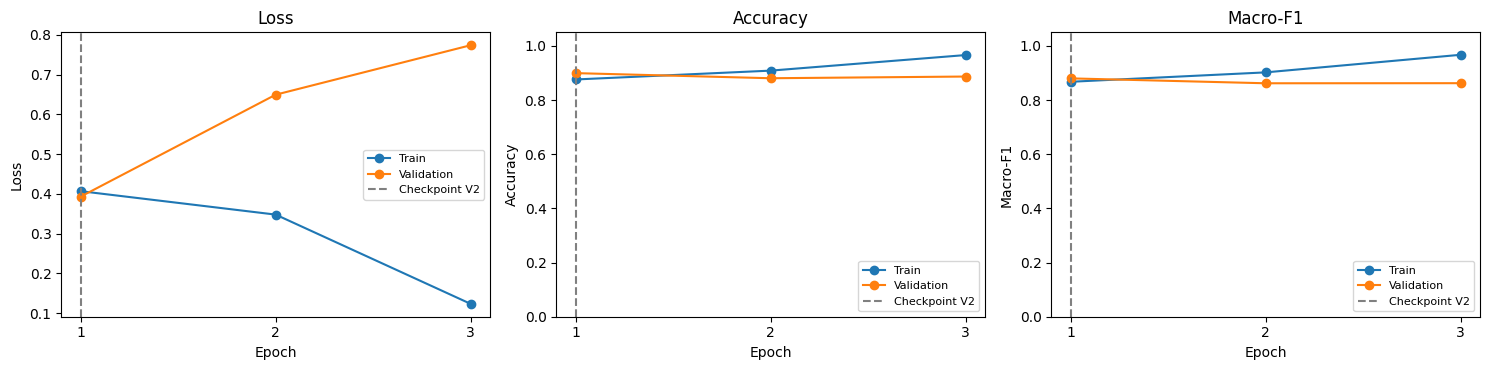

In [32]:
def plot_training_history(training_history, best_epoch):
    figure, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for axis, metric, title in zip(
        axes, ('loss', 'accuracy', 'macro_f1'), ('Loss', 'Accuracy', 'Macro-F1')
    ):
        axis.plot(training_history['epoch'], training_history['train_' + metric], marker='o', label='Train')
        axis.plot(training_history['epoch'], training_history['validation_' + metric], marker='o', label='Validation')
        axis.axvline(best_epoch, color='gray', linestyle='--', label='Checkpoint V2')
        axis.set(title=title, xlabel='Epoch', ylabel=title)
        axis.set_xticks(training_history['epoch'])
        if metric != 'loss':
            axis.set_ylim(0, 1.05)
        axis.legend(fontsize=8)
    figure.tight_layout()
    return figure

training_history_figure = plot_training_history(history, history.attrs['best_epoch'])
plt.show()


## 8. So sánh candidate V2 với baseline V1 trên cùng validation


In [33]:
validation_results = evaluate_classifier(
    model, validation_loader, DEVICE, NUM_CLASSES, criterion=criterion,
)
validation_metrics = {name: validation_results[name] for name in metric_names}
macro_f1_delta = validation_metrics['macro_f1'] - source_validation_metrics['macro_f1']
selection_decision = (
    'USE_V2_CANDIDATE' if macro_f1_delta > MIN_DELTA else 'KEEP_V1_PARENT'
)
comparison = pd.DataFrame(
    [source_validation_metrics, validation_metrics],
    index=['V1 baseline', 'V2 candidate'],
)
display(comparison.round(4))
print('Chênh lệch Macro-F1 V2 - V1:', round(macro_f1_delta, 6))
print('Quyết định theo rule đã khóa:', selection_decision)


,loss,accuracy,macro_f1,weighted_f1,balanced_accuracy
V1 baseline,0.5227,0.9308,0.9107,0.9297,0.9062
V2 candidate,0.3935,0.8994,0.8800,0.9016,0.8829


Chênh lệch Macro-F1 V2 - V1: -0.030681
Quyết định theo rule đã khóa: KEEP_V1_PARENT


In [34]:
validation_class_report = pd.DataFrame(classification_report(
    validation_results['labels'], validation_results['predictions'],
    labels=list(range(NUM_CLASSES)), target_names=ordered_labels,
    output_dict=True, zero_division=0,
)).T
display(validation_class_report.round(4))


,precision,recall,f1-score,support
governance_capital,1.0000,0.8750,0.9333,24.0000
financial_results,0.7857,0.8800,0.8302,25.0000
business_operations,0.9583,0.9388,0.9485,49.0000
legal_compliance,1.0000,0.8571,0.9231,7.0000
industry,0.8235,0.7778,0.8000,18.0000
stock_market,0.9630,0.9630,0.9630,27.0000
mention_only,0.6667,0.8889,0.7619,9.0000
accuracy,0.8994,0.8994,0.8994,0.8994
macro avg,0.8853,0.8829,0.8800,159.0000
weighted avg,0.9083,0.8994,0.9016,159.0000


## 9. Lưu candidate, provenance và quyết định validation


In [35]:
candidate_checkpoint_sha256 = hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest()
run_config = {
    'run_name': RUN_NAME,
    'run_version': 'news_type_v2_review38_incremental',
    'parent_run': SOURCE_RUN_NAME,
    'parent_run_alias': SOURCE_RUN_ALIAS,
    'parent_checkpoint_sha256': source_checkpoint_sha256,
    'initialization': 'warm_start_model_weights_new_optimizer',
    'model_name': MODEL_NAME,
    'model_revision': getattr(backbone.config, '_commit_hash', None),
    'max_length': MAX_LENGTH,
    'head_ratio': HEAD_RATIO,
    'word_segmenter': 'VnCoreNLP wseg 1.2',
    'pooling_special_tokens': 'include; padding excluded',
    'kernel_sizes': list(KERNEL_SIZES),
    'num_filters': NUM_FILTERS,
    'global_projection_size': GLOBAL_PROJECTION_SIZE,
    'dropout': DROPOUT,
    'num_classes': NUM_CLASSES,
    'label_mapping': label_mapping,
    'seed': RANDOM_SEED,
    'batch_size': BATCH_SIZE,
    'backbone_lr': BACKBONE_LR,
    'head_lr': HEAD_LR,
    'weight_decay': WEIGHT_DECAY,
    'warmup_ratio': WARMUP_RATIO,
    'max_epochs': MAX_EPOCHS,
    'patience': PATIENCE,
    'min_delta': MIN_DELTA,
    'max_grad_norm': 1.0,
    'precision': 'float32',
    'device': str(DEVICE),
    'train_rows': len(train_data),
    'review38_added_rows': len(added),
    'best_epoch': int(history.attrs['best_epoch']),
    'best_validation_macro_f1': float(history.attrs['best_validation_macro_f1']),
    'source_validation_metrics': source_validation_metrics,
    'candidate_validation_metrics': validation_metrics,
    'validation_macro_f1_delta': float(macro_f1_delta),
    'promotion_rule': 'candidate_macro_f1 > source_macro_f1 + min_delta',
    'selection_decision': selection_decision,
    'test_evaluated': False,
    'class_weights_by_id': class_weights.detach().cpu().tolist(),
    'input_sha256': v2_input_sha256,
    'source_input_sha256': v1_input_sha256,
    'review38_resolution_sha256': observed_hashes['data/annotation/news_type/review38/review38_resolution.csv'],
    'segmenter_sha256': segmenter_file_hashes,
    'candidate_checkpoint_sha256': candidate_checkpoint_sha256,
    'versions': {name: version(name) for name in (
        'torch', 'transformers', 'py-vncorenlp', 'numpy', 'pandas', 'scikit-learn',
    )},
}

selection_manifest = {
    'decision': selection_decision,
    'selected_run': RUN_NAME if selection_decision == 'USE_V2_CANDIDATE' else SOURCE_RUN_NAME,
    'source_run': SOURCE_RUN_NAME,
    'candidate_run': RUN_NAME,
    'source_validation_metrics': source_validation_metrics,
    'candidate_validation_metrics': validation_metrics,
    'macro_f1_delta': float(macro_f1_delta),
    'min_delta': MIN_DELTA,
    'test_evaluated': False,
}


In [36]:
RUN_REPORT_DIR.mkdir(parents=True, exist_ok=False)
tokenizer.save_pretrained(str(RUN_MODEL_DIR / 'tokenizer'))
backbone.config.save_pretrained(str(RUN_MODEL_DIR / 'backbone'))
(RUN_MODEL_DIR / 'run_config.json').write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
)
(RUN_REPORT_DIR / 'selection_decision.json').write_text(
    json.dumps(selection_manifest, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
)
(RUN_REPORT_DIR / 'source_validation_metrics.json').write_text(
    json.dumps(source_validation_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
)
(RUN_REPORT_DIR / 'validation_metrics.json').write_text(
    json.dumps(validation_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
)
history.to_csv(RUN_REPORT_DIR / 'training_history.csv', index=False, encoding='utf-8-sig')
validation_class_report.to_csv(
    RUN_REPORT_DIR / 'validation_classification_report.csv', encoding='utf-8-sig',
)
training_history_figure.savefig(RUN_REPORT_DIR / 'training_curves.png', dpi=160)
print('Đã lưu candidate V2 và báo cáo validation:', RUN_NAME)


Đã lưu candidate V2 và báo cáo validation: review38_incremental_v2


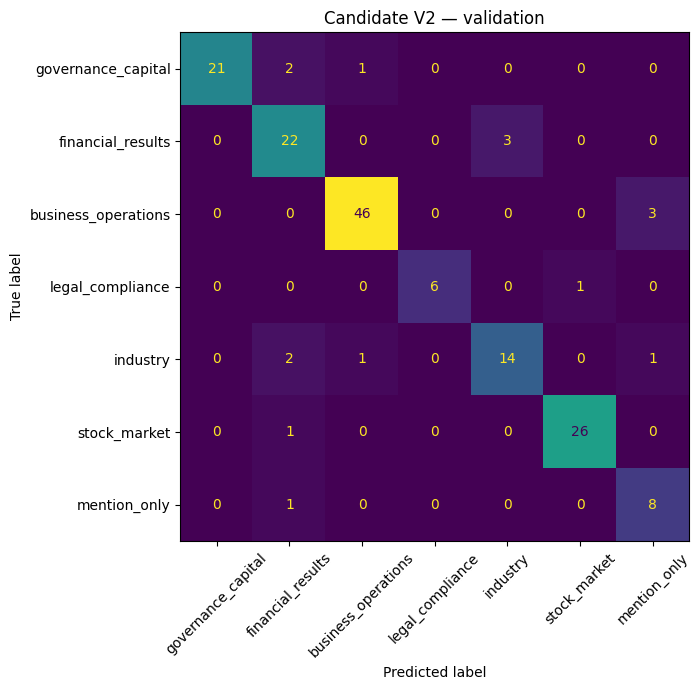

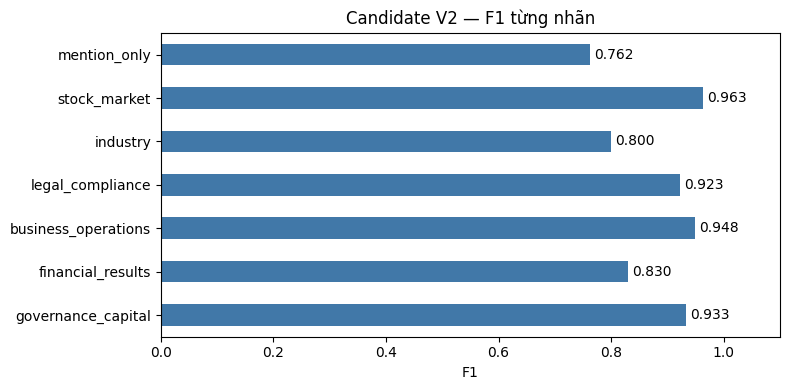

In [37]:
validation_confusion = confusion_matrix(
    validation_results['labels'], validation_results['predictions'],
    labels=list(range(NUM_CLASSES)),
)
figure, axis = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(validation_confusion, display_labels=ordered_labels).plot(
    ax=axis, xticks_rotation=45, colorbar=False,
)
axis.set_title('Candidate V2 — validation')
figure.tight_layout()
figure.savefig(RUN_REPORT_DIR / 'validation_confusion_matrix.png', dpi=160)
plt.show()

class_f1 = validation_class_report.loc[ordered_labels, 'f1-score']
axis = class_f1.plot.barh(figsize=(8, 4), color='#4178A8')
axis.bar_label(axis.containers[0], fmt='%.3f', padding=3)
axis.set(title='Candidate V2 — F1 từng nhãn', xlabel='F1', ylabel='', xlim=(0, 1.1))
axis.figure.tight_layout()
axis.figure.savefig(RUN_REPORT_DIR / 'validation_class_f1.png', dpi=160)
plt.show()


## 10. Rà lỗi validation

Bảng dưới đây dùng candidate V2 vừa train. Không tự sửa nhãn, không chuyển validation sang train và không dùng test để chọn model.


In [38]:
if (validation_loader.dataset is not validation_dataset
        or not isinstance(validation_loader.sampler, SequentialSampler)
        or validation_loader.drop_last):
    raise ValueError('Validation phải giữ đúng thứ tự và đủ mọi bài.')
dataset_labels = [int(record['labels']) for record in validation_dataset.records]
if dataset_labels != validation_data['label_id'].tolist():
    raise ValueError('Thứ tự nhãn validation không khớp dữ liệu.')

validation_review, validation_errors, validation_confusion_pairs = build_validation_review(
    validation_data, train_data, validation_results, label2id,
    encodings=validation_encodings,
)
assert len(validation_errors) == int(validation_review['false_negatives'].sum())
print(f'Validation: {len(validation_errors)}/{len(validation_data)} bài dự đoán sai.')


Validation: 16/159 bài dự đoán sai.


In [39]:
review_columns = [
    'news_type', 'train_count', 'validation_count', 'false_negatives',
    'false_positives', 'f1', 'most_confused_with', 'confusion_count',
]
display(validation_review[review_columns].round({'f1': 4}))
display(validation_confusion_pairs)
error_columns = [
    'news_id', 'title', 'news_type', 'predicted_news_type',
    'predicted_probability', 'was_truncated',
]
with pd.option_context('display.max_colwidth', 90):
    display(validation_errors[error_columns].round({'predicted_probability': 4}))


,news_type,train_count,validation_count,false_negatives,false_positives,f1,most_confused_with,confusion_count
0,mention_only,61,9,1,4,0.7619,financial_results,1
1,industry,66,18,4,3,0.8000,financial_results,2
2,financial_results,129,25,3,6,0.8302,industry,3
3,legal_compliance,37,7,1,0,0.9231,stock_market,1
4,governance_capital,113,24,3,0,0.9333,financial_results,2
5,business_operations,215,49,3,2,0.9485,mention_only,3
6,stock_market,145,27,1,1,0.9630,financial_results,1


,news_type,predicted_news_type,article_count
0,business_operations,mention_only,3
1,financial_results,industry,3
2,governance_capital,financial_results,2
3,industry,financial_results,2
4,governance_capital,business_operations,1
5,industry,business_operations,1
6,industry,mention_only,1
7,legal_compliance,stock_market,1
8,mention_only,financial_results,1
9,stock_market,financial_results,1


,news_id,title,news_type,predicted_news_type,predicted_probability,was_truncated
0,1d85806da71bbed30f87fb08768b156742ad9bb28ec7debb0b5f343c2eea0098,MWG Rank Among Top 20 Most Sustainable Companies By The Vietnam Sustainability Index (...,business_operations,mention_only,0.9982,True
1,0b62b4a402b65634abfec7a0c9954fea7bce739ba75d5c9b51ae355213e481ee,MWG Honored With “Green Star” Merit At 2025 Sustainable Development Forum,business_operations,mention_only,0.9963,True
2,8f3b6863e7d78a8d1553c16bceb164c9ca61ec4250d9e4c691d3350dd8663d43,"Giá cá tra hạ nhiệt, VCBS dự báo lợi nhuận Vĩnh Hoàn và Nam Việt tăng trưởng âm trong ...",financial_results,industry,0.9861,True
3,501849a101dd8e0236562d421e0a872de2d689fd368199bb68fce0e9ede53b7c,"CEO Sabeco: Chúng tôi ủng hộ hoàn toàn Nghị định 100, đã uống thì không lái",industry,business_operations,0.9777,True
4,2bb5ece3d635099fa0cc711dd2d923b922bd900bca4777e499c45d141e0e1a1c,"Một doanh nghiệp có doanh thu vượt xa Vingroup, gấp đôi Thế Giới Di Động, Hòa Phát, Vi...",mention_only,financial_results,0.9583,True
5,f9eff17b1b1cb9b961ed1cf16721fb3ea78a9cf4a6fb27984a247c69e14febca,FPT Retail trình chia cổ tức 2021 tỷ lệ 55%,governance_capital,financial_results,0.9537,True
6,f764800f1a979ed200736344eb406c0ffdee1c51dbf88401216740abe2f1a47f,MWG's ambition in 2023: Dominating the market worth 58 trillion dong,business_operations,mention_only,0.8580,True
7,8a1b31472ef1dcdd1e9ebbdfeccea48a8f4df4192e6aa3c1531287ca7d5d179c,"Giá vàng miếng, vàng nhẫn tăng mạnh, PNJ lãi lớn",financial_results,industry,0.8289,True
8,2682e4f977e7dfcbe4f1f436b76b099ebf0585c739a9fe54fca3689dbeb3f144,"HSBC nâng định giá MSR lên 2,9 tỷ USD: Điều gì đang thay đổi tại Masan?",stock_market,financial_results,0.7890,True
9,f52e0fbda1db9bac08cce9aef325ec5418d0ebc1047ce94729357c513728e68f,"Thanh tra SJC, Doji, PNJ, Bảo Tín Minh Châu kinh doanh vàng: Ai lỗ, lãi mạnh nhất?",financial_results,industry,0.7363,True


In [40]:
for filename, table in {
    'validation_review_summary.csv': validation_review,
    'validation_errors.csv': validation_errors,
}.items():
    table.to_csv(RUN_REPORT_DIR / filename, index=False, encoding='utf-8-sig')
print('Bảng rà lỗi:', RUN_REPORT_DIR)


Bảng rà lỗi: /content/drive/MyDrive/stock_news_anomaly_project/reports/news_type/v2/runs/review38_incremental_v2


## 11. Test — chưa chạy

Notebook này dừng sau validation. Chỉ sau khi người dùng chấp nhận `selection_decision.json` mới chuẩn bị bước test riêng cho model được chọn. Không quay lại thay cấu hình sau khi xem test.


In [41]:
if EVALUATE_TEST:
    raise RuntimeError('Test bị khóa trong Notebook 05 V2 này.')
print('Test chưa được mã hóa hoặc đánh giá.')


Test chưa được mã hóa hoặc đánh giá.


## Kết quả cần đọc

1. `selection_decision`: `USE_V2_CANDIDATE` hoặc `KEEP_V1_PARENT`.
2. Bảng V1/V2 trên cùng validation và Macro-F1 từng nhãn.
3. `validation_errors.csv` để hiểu lỗi, không dùng để sửa validation theo dự đoán.

V2 train lại trên toàn bộ dữ liệu cũ + mới để hạn chế quên kiến thức cũ; đây là warm-start có rehearsal dữ liệu, không phải resume optimizer. Tham khảo: [PhoBERT](https://arxiv.org/abs/2003.00744), [Experience Replay for Continual Learning](https://arxiv.org/abs/1811.11682), và [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).
